In [ ]:
# PROJETO FINAL — CIÊNCIA DE DADOS COM PYTHON
# Classificação de letras explícitas em músicas brasileiras

# 1. INSTALAÇÃO DAS BIBLIOTECAS
%pip -q install pandas numpy matplotlib seaborn scikit-learn


# 2. IMPORTAÇÃO DAS BIBLIOTECAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from urllib.request import urlretrieve

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Endereços dos arquivos CSV utilizados no projeto.
URL_TREINO = (
    "https://raw.githubusercontent.com/AlcilenySilva/"
    "Bert-musicas/refs/heads/main/train.csv"
)

URL_TESTE = (
    "https://raw.githubusercontent.com/AlcilenySilva/"
    "Bert-musicas/refs/heads/main/test.csv"
)

COL_TEXTO = "lyrics"
COL_ALVO = "explicit"


In [ ]:
# 3. OBTENÇÃO DOS DADOS

# Os arquivos são baixados e lidos pelo Pandas.
# O tratamento de exceção informa o problema caso o download falhe.

try:
    urlretrieve(URL_TREINO, "train.csv")
    urlretrieve(URL_TESTE, "test.csv")

    treino_original = pd.read_csv("train.csv")
    teste_original = pd.read_csv("test.csv")

except Exception as erro:
    raise RuntimeError(
        "Não foi possível baixar ou ler os arquivos CSV. "
        "Verifique a conexão e os endereços dos arquivos."
    ) from erro

print("Dimensão do arquivo de treino:", treino_original.shape)
print("Dimensão do arquivo de teste:", teste_original.shape)

display(treino_original.head())


Dimensão do arquivo de treino: (402, 10)
Dimensão do arquivo de teste: (101, 10)


,artist,title,album,lyrics,explicit,explict,Artist,Title,Album,Lyrics
0,Anitta,Maratona De Jogação,Ensaios Da Anitta,HITMAKER!\n\nAtenção!\nPrepara que agora a mar...,False,NaN,NaN,NaN,NaN,NaN
1,Slipmami,Chris Drew,Malvatrem,Hoje lembrei daquele cara emozinho e pá\nQuand...,True,NaN,NaN,NaN,NaN,NaN
2,BK,BOM TE ENCONTRAR,VERÃO CRIMINOSO,Hoje foi bom te encontrar\n\nAgora tá tudo bem...,True,NaN,NaN,NaN,NaN,NaN
3,Racionais MC's,De Volta A Cena,"Nada Como um Dia Após o Outro Dia, Vol. 1 & 2","É tru, Racionais tá aí de novo, morô?\nE os ca...",False,NaN,NaN,NaN,NaN,NaN
4,Projota,Vale Das Sombras,Tempestade Numa Gota D'Água,"Eu segui, eu segui, eu nem vi, eu nem sei\nSó ...",False,NaN,NaN,NaN,NaN,NaN


In [ ]:
# 4. VERIFICAÇÃO DAS COLUNAS

# O projeto espera uma coluna com o texto da letra e outra com o rótulo.
# Caso os nomes sejam diferentes no arquivo, ajuste COL_TEXTO e COL_ALVO.

print("Colunas do treino:", treino_original.columns.tolist())
print("Colunas do teste:", teste_original.columns.tolist())

for nome, dados in {
    "treino": treino_original,
    "teste": teste_original
}.items():

    colunas_ausentes = {COL_TEXTO, COL_ALVO} - set(dados.columns)

    if colunas_ausentes:
        raise ValueError(
            f"Colunas ausentes no arquivo de {nome}: {colunas_ausentes}. "
            "Confira os nomes das colunas e ajuste COL_TEXTO ou COL_ALVO."
        )

print("\nValores encontrados na coluna de classificação:")
print(treino_original[COL_ALVO].value_counts(dropna=False))


Colunas do treino: ['artist', 'title', 'album', 'lyrics', 'explicit', 'explict', 'Artist', 'Title', 'Album', 'Lyrics']
Colunas do teste: ['artist', 'title', 'album', 'lyrics', 'explicit', 'explict', 'Artist', 'Title', 'Album', 'Lyrics']

Valores encontrados na coluna de classificação:
explicit
True     207
False    195
Name: count, dtype: int64


In [ ]:
# 5. LIMPEZA E PREPARAÇÃO DOS DADOS

def preparar_dados(df):
    """
    Vai selecionar as colunas necessárias e realizar a limpeza:
    - remover registros sem texto ou rótulo;
    - remover textos vazios;
    - converter o rótulo para número;
    - manter somente as classes 0 e 1;
    - remover duplicatas exatas dentro do arquivo.
    """

    dados = df[[COL_TEXTO, COL_ALVO]].copy()

    # Remove registros sem texto ou sem classificação.
    dados = dados.dropna(subset=[COL_TEXTO, COL_ALVO])

    # Padroniza os textos como strings e remove espaços externos.
    dados[COL_TEXTO] = dados[COL_TEXTO].astype(str).str.strip()

    # Remove letras vazias.
    dados = dados[dados[COL_TEXTO] != ""]

    # Converte os rótulos para números.
    dados[COL_ALVO] = pd.to_numeric(
        dados[COL_ALVO],
        errors="coerce"
    )

    # Remove rótulos que não puderam ser convertidos.
    dados = dados.dropna(subset=[COL_ALVO])

    dados[COL_ALVO] = dados[COL_ALVO].astype(int)

   # Mantém apenas as classes esperadas usando NumPy.
    classes_validas = np.array([0, 1])

    dados = dados[
        np.isin(dados[COL_ALVO], classes_validas)
    ]

    # Remove duplicatas exatas de texto e rótulo.
    dados = dados.drop_duplicates(
        subset=[COL_TEXTO, COL_ALVO]
    ).reset_index(drop=True)

    return dados


treino = preparar_dados(treino_original)
teste = preparar_dados(teste_original)

print("Treino após limpeza:", treino.shape)
print("Teste após limpeza:", teste.shape)

print("\nValores ausentes no treino:")
print(treino.isna().sum())

print("\nDistribuição inicial das classes no treino:")
print(treino[COL_ALVO].value_counts().sort_index())


Treino após limpeza: (393, 2)
Teste após limpeza: (96, 2)

Valores ausentes no treino:
lyrics      0
explicit    0
dtype: int64

Distribuição inicial das classes no treino:
explicit
0    188
1    205
Name: count, dtype: int64


In [ ]:
# 6. VERIFICAÇÃO DE POSSÍVEIS DUPLICATAS ENTRE TREINO E TESTE

# Letras repetidas nos dois arquivos podem tornar a avaliação otimista, porq o modelo pode ser testado em textos que já apareceram no treino.

letras_treino = set(treino[COL_TEXTO])
letras_teste = set(teste[COL_TEXTO])

duplicatas_entre_arquivos = letras_treino.intersection(letras_teste)

print(
    "\nQuantidade de textos presentes nos dois arquivos:",
    len(duplicatas_entre_arquivos)
)

if duplicatas_entre_arquivos:
    print(
        "Atenção: existem textos repetidos entre treino e teste. "
        "Isso deve ser considerado como limitação na interpretação "
        "das métricas."
    )
else:
    print("Não foram encontrados textos idênticos entre treino e teste.")



Quantidade de textos presentes nos dois arquivos: 2
Atenção: existem textos repetidos entre treino e teste. Isso deve ser considerado como limitação na interpretação das métricas.


Resumo da quantidade de palavras e caracteres por classe:


quantidade_palavras                                              \
                       count        mean         std   min    25%    50%   
explicit                                                                   
0                      188.0  396.787234  187.955500  97.0  239.0  358.0   
1                      205.0  368.643902  205.807008  23.0  241.0  357.0   

                        quantidade_caracteres                            \
            75%     max                 count         mean          std   
explicit                                                                  
0         516.5  1101.0                 188.0  2039.755319   986.793925   
1         466.0  1324.0                 205.0  1924.858537  1080.232965   

                                                  
            min     25%     50%      75%     max  
explicit                                          
0         599.0  1214.5  1861.0  2571.75  5716.0  
1         140.0  1244.0  1869.0  2362.00  6930.0

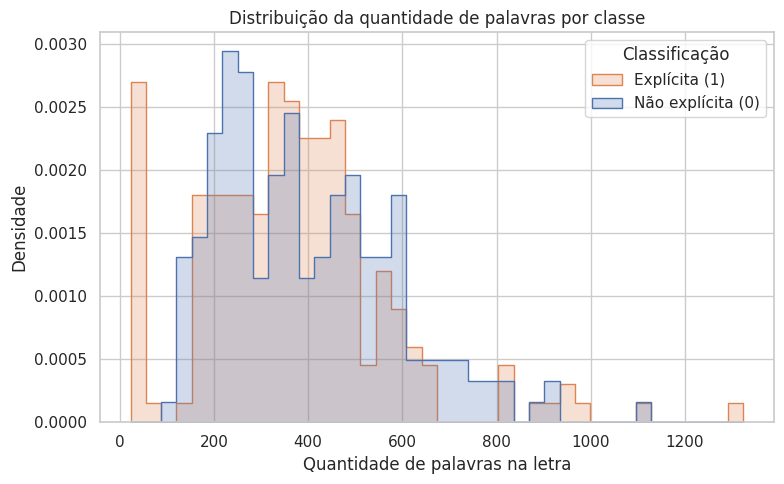

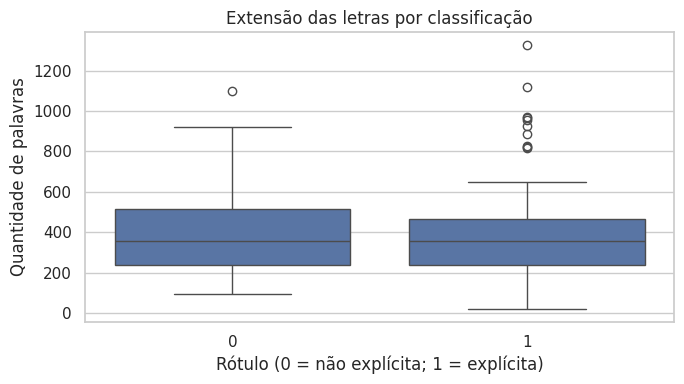

In [ ]:
# 7. ANÁLISE EXPLORATÓRIA DOS DADOS

# Cria variáveis que representam o tamanho de cada letra; q serão utilizadas apenas para análise descritiva.

treino["quantidade_palavras"] = (
    treino[COL_TEXTO].str.split().str.len()
)

treino["quantidade_caracteres"] = (
    treino[COL_TEXTO].str.len()
)

print("Resumo da quantidade de palavras e caracteres por classe:")
display(
    treino.groupby(COL_ALVO)[
        ["quantidade_palavras", "quantidade_caracteres"]
    ].describe()
)


# 7.1 DISTRIBUIÇÃO DA QUANTIDADE DE PALAVRAS

plt.figure(figsize=(8, 5))

sns.histplot(
    data=treino,
    x="quantidade_palavras",
    hue=COL_ALVO,
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Distribuição da quantidade de palavras por classe")
plt.xlabel("Quantidade de palavras na letra")
plt.ylabel("Densidade")
plt.legend(
    title="Classificação",
    labels=["Explícita (1)", "Não explícita (0)"]
)
plt.tight_layout()
plt.show()


# 7.2 COMPARAÇÃO DA EXTENSÃO DAS LETRAS

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=treino,
    x=COL_ALVO,
    y="quantidade_palavras"
)

plt.title("Extensão das letras por classificação")
plt.xlabel("Rótulo (0 = não explícita; 1 = explícita)")
plt.ylabel("Quantidade de palavras")

plt.tight_layout()
plt.show()


In [ ]:
# 8. MODELAGEM — CLASSIFICAÇÃO BINÁRIA

# TF-IDF transforma os textos em representações numéricas.
# A Regressão Logística aprende padrões associados aos rótulos existentes.
# Não há uma lista de palavras explícitas escrita manualmente no modelo. A aprendizagem depende dos exemplos e rótulos fornecidos no dataset.

X = treino[COL_TEXTO]
y = treino[COL_ALVO]

# Divide os dados em treino e validação.
# stratify=y procura preservar a proporção das classes nos dois grupos.

try:
    X_treino, X_validacao, y_treino, y_validacao = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=y
    )

except ValueError as erro:
    raise ValueError(
        "Não foi possível dividir os dados de forma estratificada. "
        "Verifique se existem exemplos suficientes em cada classe."
    ) from erro


# Pipeline reúne a transformação do texto e o classificador.
# Assim, o TF-IDF é ajustado apenas com os dados de treinamento.

modelo = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2
        )
    ),
    (
        "classificador",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    )
])

modelo.fit(X_treino, y_treino)

pred_validacao = modelo.predict(X_validacao)

print("Resultados da validação:")
print(
    classification_report(
        y_validacao,
        pred_validacao,
        labels=[0, 1],
        target_names=["Não explícita", "Explícita"],
        zero_division=0
    )
)


Resultados da validação:
               precision    recall  f1-score   support

Não explícita       0.71      0.79      0.75        38
    Explícita       0.78      0.71      0.74        41

     accuracy                           0.75        79
    macro avg       0.75      0.75      0.75        79
 weighted avg       0.75      0.75      0.75        79



In [ ]:
# 9. AVALIAÇÃO FINAL NO CONJUNTO DE TESTE

# O conjunto de teste é utilizado somente após o treinamento.
# Ele permite verificar o desempenho em exemplos separados.

X_teste = teste[COL_TEXTO]
y_teste = teste[COL_ALVO]

pred_teste = modelo.predict(X_teste)

print("Resultados no conjunto de teste:")
print(
    classification_report(
        y_teste,
        pred_teste,
        labels=[0, 1],
        target_names=["Não explícita", "Explícita"],
        zero_division=0
    )
)

print("Acurácia:", accuracy_score(y_teste, pred_teste))
print(
    "Precisão:",
    precision_score(y_teste, pred_teste, zero_division=0)
)
print(
    "Recall:",
    recall_score(y_teste, pred_teste, zero_division=0)
)
print(
    "F1-score:",
    f1_score(y_teste, pred_teste, zero_division=0)
)



Resultados no conjunto de teste:
               precision    recall  f1-score   support

Não explícita       0.84      0.72      0.77        50
    Explícita       0.74      0.85      0.79        46

     accuracy                           0.78        96
    macro avg       0.79      0.78      0.78        96
 weighted avg       0.79      0.78      0.78        96

Acurácia: 0.78125
Precisão: 0.7358490566037735
Recall: 0.8478260869565217
F1-score: 0.7878787878787878


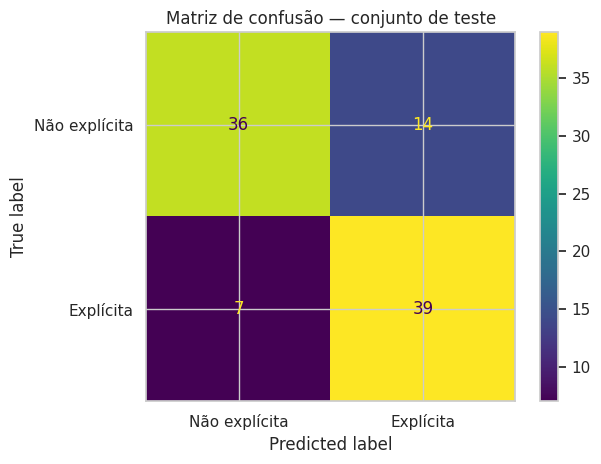

In [ ]:
# 10. MATRIZ DE CONFUSÃO

# A matriz mostra a quantidade de acertos e erros por classe, e ajuda a identificar falsos positivos e falsos negativos.

matriz = confusion_matrix(
    y_teste,
    pred_teste,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Não explícita", "Explícita"]
)

disp.plot(values_format="d")

plt.title("Matriz de confusão — conjunto de teste")
plt.tight_layout()
plt.show()


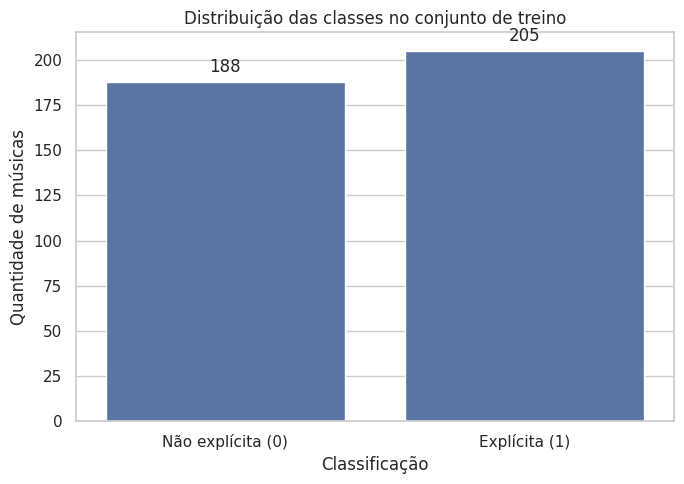

Distribuição final das classes:
explicit
Não explícita    188
Explícita        205
Name: count, dtype: int64


In [ ]:
# 11. GRÁFICO FINAL — DISTRIBUIÇÃO DAS CLASSES

# Este gráfico mostra a quantidade de registros em cada classe após a limpeza dos dados.
# Útil para verificar se existe equilíbrio entre as classes.

contagem_classes = treino[COL_ALVO].value_counts().reindex(
    [0, 1],
    fill_value=0
)

nomes_classes = ["Não explícita (0)", "Explícita (1)"]

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=nomes_classes,
    y=contagem_classes.values
)

plt.title("Distribuição das classes no conjunto de treino")
plt.xlabel("Classificação")
plt.ylabel("Quantidade de músicas")

# Exibe o número de registros acima de cada barra.
for barra in ax.patches:
    altura = barra.get_height()
    ax.annotate(
        f"{int(altura)}",
        (barra.get_x() + barra.get_width() / 2, altura),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

print("Distribuição final das classes:")
print(contagem_classes.rename(index={
    0: "Não explícita",
    1: "Explícita"
}))